In [5]:
import pandas as pd

filosofi = pd.read_csv(
    "DS_FILOSOFI_CC_2023_data.csv",
    sep=";",
    low_memory=False
)

print("Dimensions :", filosofi.shape)

print("\nColonnes :")
print(filosofi.columns.tolist())

print("\nPremières lignes :")
display(filosofi.head())

print("\nValeurs manquantes :")
print(filosofi.isna().sum())

Dimensions : (1123173, 9)

Colonnes :
['GEO', 'GEO_OBJECT', 'FILOSOFI_MEASURE', 'UNIT_MULT', 'UNIT_MEASURE', 'CONF_STATUS', 'OBS_STATUS', 'TIME_PERIOD', 'OBS_VALUE']

Premières lignes :


,GEO,GEO_OBJECT,FILOSOFI_MEASURE,UNIT_MULT,UNIT_MEASURE,CONF_STATUS,OBS_STATUS,TIME_PERIOD,OBS_VALUE
0,097,AAV2020,GI_SL,0,NR,F,O,2023,NaN
1,483,AAV2020,GI_SL,0,NR,F,O,2023,NaN
2,249,AAV2020,GI_SL,0,NR,F,O,2023,NaN
3,580,AAV2020,GI_SL,0,NR,F,O,2023,NaN
4,471,AAV2020,GI_SL,0,NR,F,O,2023,NaN



Valeurs manquantes :
GEO                       0
GEO_OBJECT                0
FILOSOFI_MEASURE          0
UNIT_MULT                 0
UNIT_MEASURE              0
CONF_STATUS               0
OBS_STATUS                0
TIME_PERIOD               0
OBS_VALUE           1070716
dtype: int64


In [6]:
# Répartition des observations par niveau géographique
print(filosofi["GEO_OBJECT"].value_counts(dropna=False))

# Vérifier spécifiquement les départements
dep = filosofi[filosofi["GEO_OBJECT"] == "DEP"]

print("\nNombre de lignes départementales :", len(dep))

print("\nExemples de codes départementaux :")
print(dep["GEO"].drop_duplicates().head(30).to_list())

COM        938736
UU2020      65610
BV2022      45630
EPCI        33345
AAV2020     18603
ARR          8748
ZE2020       7857
DEP          2619
ARM          1215
OTHER         405
REG           378
FRANCE         27
Name: GEO_OBJECT, dtype: int64

Nombre de lignes départementales : 2619

Exemples de codes départementaux :
['46', '51', '39', '49', '55', '41', '53', '48', '82', '80', '84', '87', '85', '76', '89', '90', '88', '08', '28', '2B', '33', '23', '29', '32', '36', '01', '95', '09', '17', '06']


In [7]:
# Liste des indicateurs
print("Nombre d'indicateurs :",
      filosofi["FILOSOFI_MEASURE"].nunique())

print("\nRépartition des indicateurs :")
print(filosofi["FILOSOFI_MEASURE"].value_counts())

# Vérifier les unités
print("\nUnités :")
print(
    filosofi.groupby(
        ["FILOSOFI_MEASURE", "UNIT_MEASURE", "UNIT_MULT"],
        dropna=False
    ).size().reset_index(name="nombre_lignes")
)


Nombre d'indicateurs : 27

Répartition des indicateurs :
GI_SL                   41599
D4_SL                   41599
PR_MD60                 41599
S_DIR_TAX_DI            41599
S_SOC_BEN_DI_MIN_SOC    41599
D8_SL                   41599
S_EI_DI_UNE             41599
S_SOC_BEN_DI            41599
S_INC_ASS_DI            41599
S_SOC_BEN_DI_FAM_BEN    41599
S_RET_PEN_DI            41599
D6_SL                   41599
IQR_SL                  41599
S80S20_SL               41599
Q3_SL                   41599
D1_SL                   41599
D3_SL                   41599
S_EI_DI_SAL             41599
Q1_SL                   41599
D7_SL                   41599
IR_D9_D1_SL             41599
S_EI_DI                 41599
S_EI_DI_N_SAL           41599
D9_SL                   41599
D2_SL                   41599
S_SOC_BEN_DI_HOU_BEN    41599
MED_SL                  41599
Name: FILOSOFI_MEASURE, dtype: int64

Unités :
        FILOSOFI_MEASURE UNIT_MEASURE  UNIT_MULT  nombre_lignes
0                  D1_

In [8]:
# Taux de valeurs manquantes par indicateur
missing = (
    filosofi.groupby("FILOSOFI_MEASURE")
    .agg(
        nombre_lignes=("OBS_VALUE", "size"),
        valeurs_manquantes=("OBS_VALUE", lambda x: x.isna().sum())
    )
)

missing["taux_manquant_pct"] = (
    missing["valeurs_manquantes"] /
    missing["nombre_lignes"] * 100
).round(2)

display(missing.sort_values(
    "taux_manquant_pct",
    ascending=False
))


,nombre_lignes,valeurs_manquantes,taux_manquant_pct
FILOSOFI_MEASURE,,,
D1_SL,41599,41487,99.73
Q3_SL,41599,41487,99.73
S_SOC_BEN_DI_HOU_BEN,41599,41487,99.73
S_SOC_BEN_DI_FAM_BEN,41599,41487,99.73
S_SOC_BEN_DI,41599,41487,99.73
S_RET_PEN_DI,41599,41487,99.73
S_INC_ASS_DI,41599,41487,99.73
S_EI_DI_UNE,41599,41487,99.73
S_EI_DI_SAL,41599,41487,99.73


In [9]:
# Valeurs disponibles par niveau géographique et indicateur
disponibilite = (
    filosofi.groupby(
        ["GEO_OBJECT", "FILOSOFI_MEASURE"]
    )["OBS_VALUE"]
    .agg(
        nombre_total="size",
        nombre_disponible="count"
    )
    .reset_index()
)

disponibilite["taux_disponibilite"] = (
    disponibilite["nombre_disponible"] /
    disponibilite["nombre_total"] * 100
).round(2)

display(disponibilite)

,GEO_OBJECT,FILOSOFI_MEASURE,nombre_total,nombre_disponible,taux_disponibilite
0,AAV2020,D1_SL,689,0,0.0
1,AAV2020,D2_SL,689,0,0.0
2,AAV2020,D3_SL,689,0,0.0
3,AAV2020,D4_SL,689,0,0.0
4,AAV2020,D6_SL,689,0,0.0
...,...,...,...,...,...
319,ZE2020,S_RET_PEN_DI,291,0,0.0
320,ZE2020,S_SOC_BEN_DI,291,0,0.0
321,ZE2020,S_SOC_BEN_DI_FAM_BEN,291,0,0.0
322,ZE2020,S_SOC_BEN_DI_HOU_BEN,291,0,0.0


In [10]:
bilan_dep = (
    dep.groupby("FILOSOFI_MEASURE")
    .agg(
        total=("OBS_VALUE", "size"),
        disponibles=("OBS_VALUE", "count"),
        manquantes=("OBS_VALUE", lambda x: x.isna().sum())
    )
)

bilan_dep["taux_disponibilite_pct"] = (
    bilan_dep["disponibles"] /
    bilan_dep["total"] * 100
).round(2)

display(
    bilan_dep.sort_values(
        "taux_disponibilite_pct",
        ascending=False
    )
)


,total,disponibles,manquantes,taux_disponibilite_pct
FILOSOFI_MEASURE,,,,
D1_SL,97,97,0,100.0
Q3_SL,97,97,0,100.0
S_SOC_BEN_DI_HOU_BEN,97,97,0,100.0
S_SOC_BEN_DI_FAM_BEN,97,97,0,100.0
S_SOC_BEN_DI,97,97,0,100.0
S_RET_PEN_DI,97,97,0,100.0
S_INC_ASS_DI,97,97,0,100.0
S_EI_DI_UNE,97,97,0,100.0
S_EI_DI_SAL,97,97,0,100.0


In [11]:
# Nombre de départements disposant d'une valeur
couverture = (
    dep.groupby("FILOSOFI_MEASURE")
    .agg(
        nb_departements=("GEO", "nunique"),
        nb_valeurs=("OBS_VALUE", "count")
    )
    .sort_values("nb_departements", ascending=False)
)

display(couverture)

# Examiner les valeurs disponibles pour les deux indicateurs prioritaires
prioritaires = dep[
    dep["FILOSOFI_MEASURE"].isin(["MED_SL", "PR_MD60"])
]

display(
    prioritaires[
        ["GEO", "FILOSOFI_MEASURE", "OBS_VALUE",
         "UNIT_MEASURE", "OBS_STATUS", "CONF_STATUS"]
    ].head(30)
)


,nb_departements,nb_valeurs
FILOSOFI_MEASURE,,
D1_SL,97,97
Q3_SL,97,97
S_SOC_BEN_DI_HOU_BEN,97,97
S_SOC_BEN_DI_FAM_BEN,97,97
S_SOC_BEN_DI,97,97
S_RET_PEN_DI,97,97
S_INC_ASS_DI,97,97
S_EI_DI_UNE,97,97
S_EI_DI_SAL,97,97


,GEO,FILOSOFI_MEASURE,OBS_VALUE,UNIT_MEASURE,OBS_STATUS,CONF_STATUS
1007461,49,PR_MD60,11.8,PT,A,F
1007467,48,MED_SL,24270.0,EUR_YR,A,F
1007485,84,MED_SL,23840.0,EUR_YR,A,F
1007640,09,MED_SL,23360.0,EUR_YR,A,F
1007859,34,MED_SL,24280.0,EUR_YR,A,F
1007885,78,MED_SL,31520.0,EUR_YR,A,F
1008024,07,PR_MD60,15.6,PT,A,F
1008195,85,PR_MD60,9.2,PT,A,F
1008198,94,MED_SL,27250.0,EUR_YR,A,F
1008269,36,PR_MD60,15.8,PT,A,F


In [12]:

# 1. Préparer une copie des données départementales
dep_clean = dep.copy()

# 2. Conserver les codes départementaux sous forme de texte
dep_clean["GEO"] = (
    dep_clean["GEO"].astype(str).str.zfill(2)
)

# 3. Vérifier les doublons sur la clé département-indicateur
nb_doublons = dep_clean.duplicated(
    subset=["GEO", "FILOSOFI_MEASURE"]
).sum()

print("Nombre de doublons :", nb_doublons)

# 4. Transformer les données du format long au format large
if nb_doublons == 0:
    base_filosofi = dep_clean.pivot(
        index="GEO",
        columns="FILOSOFI_MEASURE",
        values="OBS_VALUE"
    ).reset_index()

    base_filosofi.columns.name = None

    print("\nDimensions de la nouvelle table :",
          base_filosofi.shape)

    display(base_filosofi.head())
else:
    print("Attention : vérifier les doublons avant le pivot.")


Nombre de doublons : 0

Dimensions de la nouvelle table : (97, 28)


,GEO,D1_SL,D2_SL,D3_SL,D4_SL,D6_SL,D7_SL,D8_SL,D9_SL,GI_SL,...,S_EI_DI,S_EI_DI_N_SAL,S_EI_DI_SAL,S_EI_DI_UNE,S_INC_ASS_DI,S_RET_PEN_DI,S_SOC_BEN_DI,S_SOC_BEN_DI_FAM_BEN,S_SOC_BEN_DI_HOU_BEN,S_SOC_BEN_DI_MIN_SOC
0,01,14490.0,18880.0,22320.0,25190.0,31030.0,34970.0,40830.0,53240.0,0.312,...,77.7,3.5,72.0,2.2,10.4,24.2,3.3,1.5,0.5,1.2
1,02,12600.0,15730.0,18410.0,20980.0,25770.0,28530.0,32180.0,38580.0,0.259,...,68.0,5.9,59.6,2.4,8.8,29.9,7.1,2.4,1.3,3.4
2,03,13210.0,16690.0,19570.0,22120.0,26820.0,29510.0,33150.0,39630.0,0.251,...,59.3,5.4,51.8,2.0,12.2,36.4,5.7,1.6,1.1,3.0
3,04,12690.0,15970.0,18970.0,21730.0,26930.0,29970.0,34160.0,41090.0,0.275,...,58.9,5.6,50.5,2.7,14.8,35.2,5.3,1.6,1.1,2.6
4,05,13870.0,17410.0,20260.0,22740.0,27570.0,30450.0,34510.0,41460.0,0.254,...,61.2,7.1,51.5,2.6,13.2,35.6,4.5,1.5,0.8,2.2


In [13]:

# Indicateurs retenus pour l'analyse principale
indicateurs = [
    "MED_SL",
    "PR_MD60",
    "GI_SL",
    "S80S20_SL",
    "S_EI_DI",
    "S_RET_PEN_DI",
    "S_SOC_BEN_DI"
]

# Construire la table analytique
base_analyse = base_filosofi[
    ["GEO"] + indicateurs
].copy()

# Renommer les variables
base_analyse = base_analyse.rename(columns={
    "GEO": "code_departement",
    "MED_SL": "niveau_vie_median",
    "PR_MD60": "taux_pauvrete",
    "GI_SL": "indice_gini",
    "S80S20_SL": "rapport_interdecile",
    "S_EI_DI": "part_revenus_activite",
    "S_RET_PEN_DI": "part_pensions",
    "S_SOC_BEN_DI": "part_prestations_sociales"
})

display(base_analyse.head())

print("\nDimensions :", base_analyse.shape)
print("\nValeurs manquantes :")
print(base_analyse.isna().sum())


,code_departement,niveau_vie_median,taux_pauvrete,indice_gini,rapport_interdecile,part_revenus_activite,part_pensions,part_prestations_sociales
0,01,27990.0,12.2,0.312,4.9,77.7,24.2,3.3
1,02,23360.0,19.4,0.259,3.8,68.0,29.9,7.1
2,03,24430.0,16.4,0.251,3.7,59.3,36.4,5.7
3,04,24240.0,18.6,0.275,4.1,58.9,35.2,5.3
4,05,25060.0,14.3,0.254,3.7,61.2,35.6,4.5



Dimensions : (97, 8)

Valeurs manquantes :
code_departement             0
niveau_vie_median            0
taux_pauvrete                0
indice_gini                  0
rapport_interdecile          0
part_revenus_activite        0
part_pensions                0
part_prestations_sociales    0
dtype: int64


In [14]:
import os

os.makedirs("data/processed", exist_ok=True)

base_analyse.to_csv(
    "data/processed/filosofi_departements_2023.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Fichier enregistré avec succès.")

Fichier enregistré avec succès.


In [15]:

# Sélection des indicateurs à analyser
variables = [
    "niveau_vie_median",
    "taux_pauvrete",
    "indice_gini",
    "rapport_interdecile",
    "part_revenus_activite",
    "part_pensions",
    "part_prestations_sociales"
]

# Calcul des statistiques descriptives
statistiques = base_analyse[variables].describe().T

# Sélection et renommage des statistiques
statistiques = statistiques[
    ["mean", "50%", "std", "min", "max"]
]

statistiques = statistiques.rename(columns={
    "mean": "moyenne",
    "50%": "mediane",
    "std": "ecart_type",
    "min": "minimum",
    "max": "maximum"
})

# Arrondir les résultats
statistiques = statistiques.round(2)

display(statistiques)


,moyenne,mediane,ecart_type,minimum,maximum
niveau_vie_median,25484.64,25140.00,2074.41,19110.00,33790.00
taux_pauvrete,15.91,15.60,3.81,9.20,36.40
indice_gini,0.27,0.26,0.03,0.22,0.45
rapport_interdecile,4.11,3.80,0.92,3.10,10.50
part_revenus_activite,68.01,66.70,7.38,55.40,90.40
part_pensions,30.34,30.40,5.40,16.10,40.30
part_prestations_sociales,5.21,5.00,1.45,2.10,14.70


In [16]:

# Colonnes à afficher
colonnes = [
    "code_departement",
    "taux_pauvrete",
    "niveau_vie_median",
    "indice_gini",
    "rapport_interdecile"
]

# 1. Les 10 départements les plus pauvres
top_pauvrete = (
    base_analyse
    .sort_values("taux_pauvrete", ascending=False)
    [colonnes]
    .head(10)
)

print("TOP 10 — Taux de pauvreté les plus élevés")
display(top_pauvrete.round(2))


# 2. Les 10 départements au niveau de vie le plus faible
top_bas_niveau_vie = (
    base_analyse
    .sort_values("niveau_vie_median", ascending=True)
    [colonnes]
    .head(10)
)

print("TOP 10 — Niveaux de vie médians les plus faibles")
display(top_bas_niveau_vie.round(2))


# 3. Les 10 départements présentant les inégalités les plus fortes
top_inegalites = (
    base_analyse
    .sort_values("rapport_interdecile", ascending=False)
    [colonnes]
    .head(10)
)

print("TOP 10 — Rapports interdéciles les plus élevés")
display(top_inegalites.round(2))


TOP 10 — Taux de pauvreté les plus élevés


,code_departement,taux_pauvrete,niveau_vie_median,indice_gini,rapport_interdecile
96,974,36.4,19110.0,0.33,5.2
93,93,29.5,21250.0,0.31,5.1
66,66,22.4,23080.0,0.28,4.2
29,2B,21.8,24200.0,0.31,5.0
84,84,21.4,23840.0,0.29,4.4
10,11,21.2,23060.0,0.27,4.0
30,30,21.0,23930.0,0.28,4.3
34,34,21.0,24280.0,0.30,4.7
59,59,20.7,23810.0,0.29,4.3
12,13,20.3,25610.0,0.32,5.4


TOP 10 — Niveaux de vie médians les plus faibles


,code_departement,taux_pauvrete,niveau_vie_median,indice_gini,rapport_interdecile
96,974,36.4,19110.0,0.33,5.2
93,93,29.5,21250.0,0.31,5.1
10,11,21.2,23060.0,0.27,4.0
66,66,22.4,23080.0,0.28,4.2
21,23,19.5,23210.0,0.25,3.7
62,62,19.1,23260.0,0.25,3.6
8,09,20.0,23360.0,0.26,3.8
1,02,19.4,23360.0,0.26,3.8
7,08,19.9,23500.0,0.26,3.8
47,47,18.5,23730.0,0.26,3.8


TOP 10 — Rapports interdéciles les plus élevés


,code_departement,taux_pauvrete,niveau_vie_median,indice_gini,rapport_interdecile
75,75,16.8,33650.0,0.45,10.5
92,92,13.5,33790.0,0.37,7.1
74,74,10.2,32180.0,0.34,5.7
94,94,18.4,27250.0,0.32,5.5
12,13,20.3,25610.0,0.32,5.4
5,06,17.7,26380.0,0.32,5.4
78,78,11.6,31520.0,0.32,5.3
96,974,36.4,19110.0,0.33,5.2
93,93,29.5,21250.0,0.31,5.1
28,2A,17.9,26050.0,0.32,5.1


In [25]:

noms_departements = {
    "01": "Ain",
    "02": "Aisne",
    "03": "Allier",
    "04": "Alpes-de-Haute-Provence",
    "05": "Hautes-Alpes",
    "06": "Alpes-Maritimes",
    "07": "Ardèche",
    "08": "Ardennes",
    "09": "Ariège",
    "10": "Aube",
    "11": "Aude",
    "12": "Aveyron",
    "13": "Bouches-du-Rhône",
    "14": "Calvados",
    "15": "Cantal",
    "16": "Charente",
    "17": "Charente-Maritime",
    "18": "Cher",
    "19": "Corrèze",
    "2A": "Corse-du-Sud",
    "2B": "Haute-Corse",
    "21": "Côte-d'Or",
    "22": "Côtes-d'Armor",
    "23": "Creuse",
    "24": "Dordogne",
    "25": "Doubs",
    "26": "Drôme",
    "27": "Eure",
    "28": "Eure-et-Loir",
    "29": "Finistère",
    "30": "Gard",
    "31": "Haute-Garonne",
    "32": "Gers",
    "33": "Gironde",
    "34": "Hérault",
    "35": "Ille-et-Vilaine",
    "36": "Indre",
    "37": "Indre-et-Loire",
    "38": "Isère",
    "39": "Jura",
    "40": "Landes",
    "41": "Loir-et-Cher",
    "42": "Loire",
    "43": "Haute-Loire",
    "44": "Loire-Atlantique",
    "45": "Loiret",
    "46": "Lot",
    "47": "Lot-et-Garonne",
    "48": "Lozère",
    "49": "Maine-et-Loire",
    "50": "Manche",
    "51": "Marne",
    "52": "Haute-Marne",
    "53": "Mayenne",
    "54": "Meurthe-et-Moselle",
    "55": "Meuse",
    "56": "Morbihan",
    "57": "Moselle",
    "58": "Nièvre",
    "59": "Nord",
    "60": "Oise",
    "61": "Orne",
    "62": "Pas-de-Calais",
    "63": "Puy-de-Dôme",
    "64": "Pyrénées-Atlantiques",
    "65": "Hautes-Pyrénées",
    "66": "Pyrénées-Orientales",
    "67": "Bas-Rhin",
    "68": "Haut-Rhin",
    "69": "Rhône",
    "70": "Haute-Saône",
    "71": "Saône-et-Loire",
    "72": "Sarthe",
    "73": "Savoie",
    "74": "Haute-Savoie",
    "75": "Paris",
    "76": "Seine-Maritime",
    "77": "Seine-et-Marne",
    "78": "Yvelines",
    "79": "Deux-Sèvres",
    "80": "Somme",
    "81": "Tarn",
    "82": "Tarn-et-Garonne",
    "83": "Var",
    "84": "Vaucluse",
    "85": "Vendée",
    "86": "Vienne",
    "87": "Haute-Vienne",
    "88": "Vosges",
    "89": "Yonne",
    "90": "Territoire de Belfort",
    "91": "Essonne",
    "92": "Hauts-de-Seine",
    "93": "Seine-Saint-Denis",
    "94": "Val-de-Marne",
    "95": "Val-d'Oise",
    "971": "Guadeloupe",
    "972": "Martinique",
    "973": "Guyane",
    "974": "La Réunion",
    "976": "Mayotte"
}

print("Nombre de départements référencés :", len(noms_departements))


Nombre de départements référencés : 101


In [26]:

# Sécuriser les codes départementaux
base_analyse["code_departement"] = (
    base_analyse["code_departement"].astype(str).str.strip()
)

# Ajouter le nom du département
base_analyse["nom_departement"] = (
    base_analyse["code_departement"].map(noms_departements)
)

# Vérifier les correspondances
print("Départements sans correspondance :")
display(
    base_analyse.loc[
        base_analyse["nom_departement"].isna(),
        ["code_departement"]
    ]
)

print("\nAperçu de la base enrichie :")
display(base_analyse.head(10))


Départements sans correspondance :


,code_departement



Aperçu de la base enrichie :


,code_departement,niveau_vie_median,taux_pauvrete,indice_gini,rapport_interdecile,part_revenus_activite,part_pensions,part_prestations_sociales,nom_departement
0,01,27990.0,12.2,0.312,4.9,77.7,24.2,3.3,Ain
1,02,23360.0,19.4,0.259,3.8,68.0,29.9,7.1,Aisne
2,03,24430.0,16.4,0.251,3.7,59.3,36.4,5.7,Allier
3,04,24240.0,18.6,0.275,4.1,58.9,35.2,5.3,Alpes-de-Haute-Provence
4,05,25060.0,14.3,0.254,3.7,61.2,35.6,4.5,Hautes-Alpes
5,06,26380.0,17.7,0.322,5.4,71.1,28.0,4.2,Alpes-Maritimes
6,07,24820.0,15.6,0.251,3.7,62.4,33.6,5.0,Ardèche
7,08,23500.0,19.9,0.260,3.8,65.5,30.7,6.7,Ardennes
8,09,23360.0,20.0,0.256,3.8,58.9,36.5,6.5,Ariège
9,10,24130.0,18.1,0.277,4.1,68.0,29.8,6.2,Aube


In [27]:

print("Nombre de lignes :", len(base_analyse))
print("Nombre de départements reconnus :",
      base_analyse["nom_departement"].notna().sum())

print("\nListe des départements :")
display(
    base_analyse[
        ["code_departement", "nom_departement"]
    ].sort_values("code_departement").reset_index(drop=True)
)


Nombre de lignes : 97
Nombre de départements reconnus : 97

Liste des départements :


,code_departement,nom_departement
0,01,Ain
1,02,Aisne
2,03,Allier
3,04,Alpes-de-Haute-Provence
4,05,Hautes-Alpes
...,...,...
92,92,Hauts-de-Seine
93,93,Seine-Saint-Denis
94,94,Val-de-Marne
95,95,Val-d'Oise


In [28]:

import matplotlib.pyplot as plt
import seaborn as sns

# Vérification et préparation
df_graphique = base_analyse.dropna(
    subset=[
        "nom_departement",
        "niveau_vie_median",
        "taux_pauvrete"
    ]
).copy()

print("Nombre de départements représentés :", len(df_graphique))


Nombre de départements représentés : 97


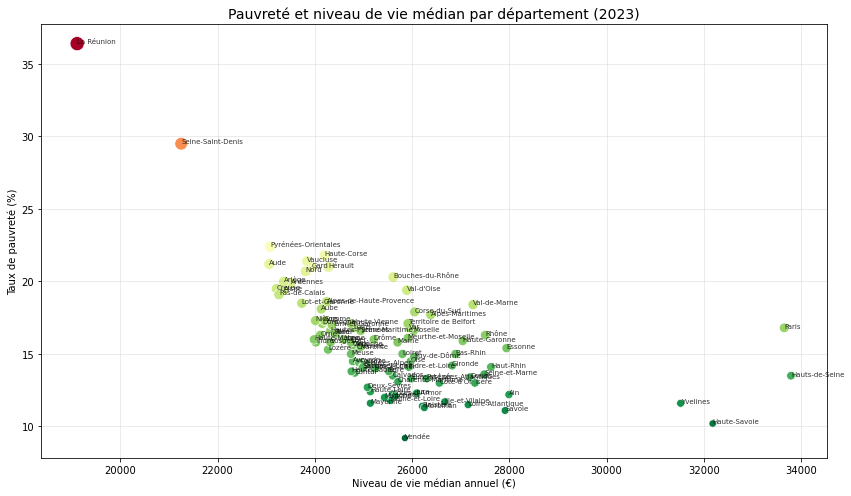

In [29]:

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=df_graphique,
    x="niveau_vie_median",
    y="taux_pauvrete",
    hue="taux_pauvrete",
    palette="RdYlGn_r",
    size="taux_pauvrete",
    sizes=(50, 200),
    legend=False
)

# Ajouter les noms des départements
for _, row in df_graphique.iterrows():
    plt.annotate(
        row["nom_departement"],
        (row["niveau_vie_median"], row["taux_pauvrete"]),
        fontsize=7,
        alpha=0.8
    )

plt.title(
    "Pauvreté et niveau de vie médian par département (2023)",
    fontsize=14
)
plt.xlabel("Niveau de vie médian annuel (€)")
plt.ylabel("Taux de pauvreté (%)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [30]:

# Corrélation entre pauvreté et niveau de vie
correlation = df_graphique[
    ["niveau_vie_median", "taux_pauvrete"]
].corr()

print("Matrice de corrélation :")
display(correlation.round(3))

# Identifier les départements extrêmes
print("\n5 départements avec le taux de pauvreté le plus élevé :")
display(
    df_graphique.nlargest(5, "taux_pauvrete")[
        ["nom_departement", "niveau_vie_median", "taux_pauvrete"]
    ]
)

print("\n5 départements avec le niveau de vie le plus élevé :")
display(
    df_graphique.nlargest(5, "niveau_vie_median")[
        ["nom_departement", "niveau_vie_median", "taux_pauvrete"]
    ]
)


Matrice de corrélation :


,niveau_vie_median,taux_pauvrete
niveau_vie_median,1.000,-0.588
taux_pauvrete,-0.588,1.000



5 départements avec le taux de pauvreté le plus élevé :


,nom_departement,niveau_vie_median,taux_pauvrete
96,La Réunion,19110.0,36.4
93,Seine-Saint-Denis,21250.0,29.5
66,Pyrénées-Orientales,23080.0,22.4
29,Haute-Corse,24200.0,21.8
84,Vaucluse,23840.0,21.4



5 départements avec le niveau de vie le plus élevé :


,nom_departement,niveau_vie_median,taux_pauvrete
92,Hauts-de-Seine,33790.0,13.5
75,Paris,33650.0,16.8
74,Haute-Savoie,32180.0,10.2
78,Yvelines,31520.0,11.6
0,Ain,27990.0,12.2


In [31]:

# Création d'une copie de travail
df_fragilite = base_analyse.copy()

# 1. Normalisation du taux de pauvreté
df_fragilite["score_pauvrete"] = (
    (df_fragilite["taux_pauvrete"] - df_fragilite["taux_pauvrete"].min())
    /
    (df_fragilite["taux_pauvrete"].max() - df_fragilite["taux_pauvrete"].min())
)

# 2. Normalisation inversée du niveau de vie
# Un niveau de vie faible correspond à une fragilité élevée
df_fragilite["score_niveau_vie"] = (
    (df_fragilite["niveau_vie_median"].max() - df_fragilite["niveau_vie_median"])
    /
    (df_fragilite["niveau_vie_median"].max() - df_fragilite["niveau_vie_median"].min())
)

# 3. Normalisation du rapport interdécile
df_fragilite["score_inegalites"] = (
    (df_fragilite["rapport_interdecile"] - df_fragilite["rapport_interdecile"].min())
    /
    (df_fragilite["rapport_interdecile"].max() - df_fragilite["rapport_interdecile"].min())
)

# 4. Calcul du score synthétique sur 100
df_fragilite["score_fragilite"] = (
    df_fragilite[
        ["score_pauvrete", "score_niveau_vie", "score_inegalites"]
    ].mean(axis=1) * 100
).round(2)

# 5. Classement des départements
classement_fragilite = (
    df_fragilite
    .sort_values("score_fragilite", ascending=False)
    [[
        "code_departement",
        "nom_departement",
        "taux_pauvrete",
        "niveau_vie_median",
        "rapport_interdecile",
        "score_fragilite"
    ]]
    .reset_index(drop=True)
)

print("TOP 10 DES DÉPARTEMENTS LES PLUS FRAGILES")
display(classement_fragilite.head(10))

print("\nTOP 10 DES DÉPARTEMENTS LES MOINS FRAGILES")
display(classement_fragilite.tail(10).sort_values("score_fragilite"))


TOP 10 DES DÉPARTEMENTS LES PLUS FRAGILES


,code_departement,nom_departement,taux_pauvrete,niveau_vie_median,rapport_interdecile,score_fragilite
0,974,La Réunion,36.4,19110.0,5.2,76.13
1,93,Seine-Saint-Denis,29.5,21250.0,5.1,62.36
2,2B,Haute-Corse,21.8,24200.0,5.0,45.78
3,66,Pyrénées-Orientales,22.4,23080.0,4.2,45.45
4,84,Vaucluse,21.4,23840.0,4.4,43.40
5,34,Hérault,21.0,24280.0,4.7,43.26
6,11,Aude,21.2,23060.0,4.0,43.12
7,75,Paris,16.8,33650.0,10.5,42.96
8,13,Bouches-du-Rhône,20.3,25610.0,5.4,42.54
9,30,Gard,21.0,23930.0,4.3,42.25



TOP 10 DES DÉPARTEMENTS LES MOINS FRAGILES


,code_departement,nom_departement,taux_pauvrete,niveau_vie_median,rapport_interdecile,score_fragilite
96,74,Haute-Savoie,10.2,32180.0,5.7,16.59
95,78,Yvelines,11.6,31520.0,5.3,18.01
94,85,Vendée,9.2,25850.0,3.1,18.03
93,73,Savoie,11.1,27910.0,3.9,19.28
92,44,Loire-Atlantique,11.5,27150.0,3.8,21.05
91,29,Finistère,11.4,26210.0,3.5,21.71
90,35,Ille-et-Vilaine,11.7,26670.0,3.7,21.93
89,56,Morbihan,11.3,26250.0,3.6,21.95
88,38,Isère,13.0,27290.0,3.9,23.02
87,49,Maine-et-Loire,11.8,25550.0,3.4,23.25


In [33]:

import pandas as pd

# Classement par quartiles
df_fragilite["categorie_fragilite"] = pd.qcut(
    df_fragilite["score_fragilite"].rank(method="first", pct=True),
    q=4,
    labels=[
        "Fragilité faible",
        "Fragilité modérée",
        "Fragilité élevée",
        "Fragilité très élevée"
    ]
)

# Nombre de départements par catégorie
repartition = (
    df_fragilite["categorie_fragilite"]
    .value_counts()
    .reindex([
        "Fragilité faible",
        "Fragilité modérée",
        "Fragilité élevée",
        "Fragilité très élevée"
    ])
    .reset_index()
)

repartition.columns = ["categorie_fragilite", "nombre_departements"]

print("Répartition des départements par niveau de fragilité :")
display(repartition)

# Score moyen par catégorie
synthese_categories = (
    df_fragilite
    .groupby("categorie_fragilite", observed=True)
    .agg(
        nombre_departements=("code_departement", "count"),
        score_moyen=("score_fragilite", "mean"),
        taux_pauvrete_moyen=("taux_pauvrete", "mean"),
        niveau_vie_moyen=("niveau_vie_median", "mean"),
        rapport_interdecile_moyen=("rapport_interdecile", "mean")
    )
    .round(2)
)

display(synthese_categories)


Répartition des départements par niveau de fragilité :


,categorie_fragilite,nombre_departements
0,Fragilité faible,25
1,Fragilité modérée,24
2,Fragilité élevée,24
3,Fragilité très élevée,24


,nombre_departements,score_moyen,taux_pauvrete_moyen,niveau_vie_moyen,rapport_interdecile_moyen
categorie_fragilite,,,,,
Fragilité faible,25,22.96,12.14,27028.00,3.99
Fragilité modérée,24,28.56,14.58,25596.25,3.85
Fragilité élevée,24,32.76,16.38,24900.83,3.94
Fragilité très élevée,24,42.64,20.68,24349.17,4.68


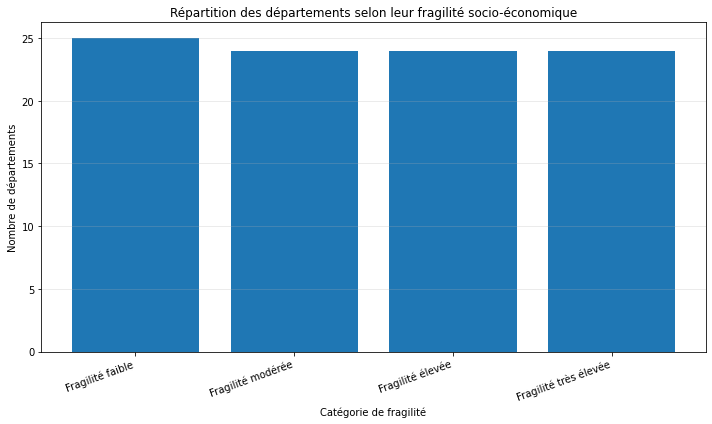

In [34]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(
    repartition["categorie_fragilite"],
    repartition["nombre_departements"]
)

plt.title("Répartition des départements selon leur fragilité socio-économique")
plt.xlabel("Catégorie de fragilité")
plt.ylabel("Nombre de départements")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


In [37]:

variables = [
    "niveau_vie_median",
    "taux_pauvrete",
    "indice_gini",
    "rapport_interdecile",
    "part_revenus_activite",
    "part_pensions",
    "part_prestations_sociales"
]

correlations = df_fragilite[variables].corr(method="pearson")

display(correlations.round(2))


,niveau_vie_median,taux_pauvrete,indice_gini,rapport_interdecile,part_revenus_activite,part_pensions,part_prestations_sociales
niveau_vie_median,1.00,-0.59,0.54,0.58,0.63,-0.48,-0.79
taux_pauvrete,-0.59,1.00,0.33,0.25,-0.04,-0.17,0.86
indice_gini,0.54,0.33,1.00,0.97,0.63,-0.68,-0.07
rapport_interdecile,0.58,0.25,0.97,1.00,0.59,-0.63,-0.14
part_revenus_activite,0.63,-0.04,0.63,0.59,1.00,-0.93,-0.18
part_pensions,-0.48,-0.17,-0.68,-0.63,-0.93,1.00,-0.03
part_prestations_sociales,-0.79,0.86,-0.07,-0.14,-0.18,-0.03,1.00


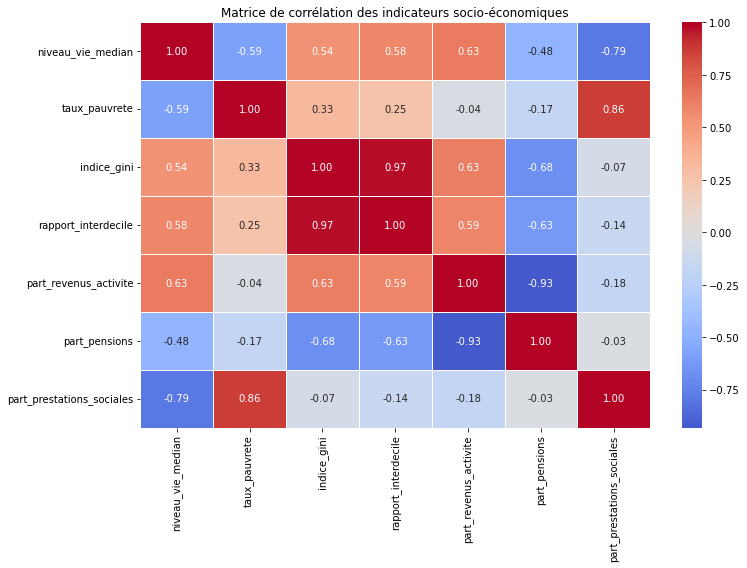

In [38]:

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlations,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f",
    linewidths=0.5
)

plt.title("Matrice de corrélation des indicateurs socio-économiques")
plt.tight_layout()
plt.show()


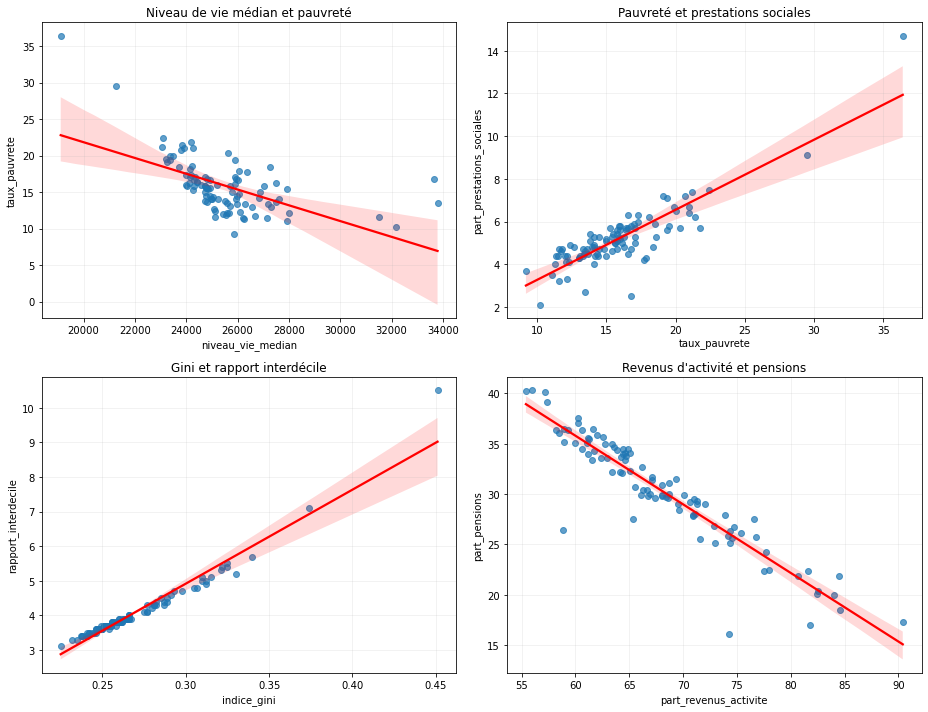

In [39]:

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

relations = [
    ("niveau_vie_median", "taux_pauvrete",
     "Niveau de vie médian et pauvreté"),
    ("taux_pauvrete", "part_prestations_sociales",
     "Pauvreté et prestations sociales"),
    ("indice_gini", "rapport_interdecile",
     "Gini et rapport interdécile"),
    ("part_revenus_activite", "part_pensions",
     "Revenus d'activité et pensions")
]

for ax, (x, y, titre) in zip(axes.flat, relations):
    sns.regplot(
        data=df_fragilite,
        x=x,
        y=y,
        ax=ax,
        scatter_kws={"alpha": 0.7},
        line_kws={"color": "red"}
    )
    ax.set_title(titre)
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()


In [40]:

relations = [
    ("niveau_vie_median", "taux_pauvrete"),
    ("taux_pauvrete", "part_prestations_sociales"),
    ("indice_gini", "rapport_interdecile"),
    ("part_revenus_activite", "part_pensions")
]

for x, y in relations:
    print(f"\nRelation : {x} / {y}")
    print("Corrélation :", round(df_fragilite[x].corr(df_fragilite[y]), 2))

    print("\nValeurs extrêmes de", x)
    display(
        df_fragilite.nlargest(3, x)[
            ["nom_departement", x, y]
        ]
    )

    print("\nValeurs extrêmes de", y)
    display(
        df_fragilite.nlargest(3, y)[
            ["nom_departement", x, y]
        ]
    )



Relation : niveau_vie_median / taux_pauvrete
Corrélation : -0.59

Valeurs extrêmes de niveau_vie_median


,nom_departement,niveau_vie_median,taux_pauvrete
92,Hauts-de-Seine,33790.0,13.5
75,Paris,33650.0,16.8
74,Haute-Savoie,32180.0,10.2



Valeurs extrêmes de taux_pauvrete


,nom_departement,niveau_vie_median,taux_pauvrete
96,La Réunion,19110.0,36.4
93,Seine-Saint-Denis,21250.0,29.5
66,Pyrénées-Orientales,23080.0,22.4



Relation : taux_pauvrete / part_prestations_sociales
Corrélation : 0.86

Valeurs extrêmes de taux_pauvrete


,nom_departement,taux_pauvrete,part_prestations_sociales
96,La Réunion,36.4,14.7
93,Seine-Saint-Denis,29.5,9.1
66,Pyrénées-Orientales,22.4,7.5


... (6 outputs left out)


Relation : part_revenus_activite / part_pensions
Corrélation : -0.93

Valeurs extrêmes de part_revenus_activite


,nom_departement,part_revenus_activite,part_pensions
92,Hauts-de-Seine,90.4,17.3
75,Paris,84.6,18.5
78,Yvelines,84.5,21.9



Valeurs extrêmes de part_pensions


,nom_departement,part_revenus_activite,part_pensions
46,Lot,56.0,40.3
21,Creuse,55.4,40.2
58,Nièvre,57.2,40.1
